# Motivating example: the values in Fig. 1 and Fig. 2

This notebook computes the bar values shown in Fig. 1 (eIRWR overview) and
Fig. 2 (evaluation pipeline) of the paper. The example is a simulated incident
on the real CG84 call graph of the Alibaba Microservice Trace Dataset, with
11,966 services. All scores come from the code in `src/` with the default
parameters of the paper.

The example shows the problem that motivates eIRWR. The root cause $D$ is not
the most anomalous service. Its caller $B$ has a higher anomaly score, so a
ranking by anomaly score blames $B$. eIRWR ranks $D$ first.

**Requirement.** The trace file `data/data/CallGraph/CallGraph_84.csv`
(see `scripts/download_data.sh`). Loading it takes one to two minutes.

| Section | Output |
| --- | --- |
| 1 | CG84 dependency graph |
| 2 | The four services of the example |
| 3 | Incident simulation |
| 4 | Values for Fig. 2: anomaly scores at $v = 0.0, 0.3, 0.5$ |
| 5 | Values for Fig. 1: anomaly scores and eIRWR scores at $v = 0.3$ |
| 6 | Why eIRWR ranks $D$ first |
| 7 | Robustness to the noise draw |
| 8 | Plots of the figure panels |

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse

# make the `src` package importable when running from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.loader import load_call_graph_by_index
from src.rca.baselines import personalized_pagerank
from src.rca.graph import (
    build_dependency_graph,
    compute_fault_propagation_matrix,
    compute_weight_matrix,
)
from src.rca.irwr import irwr, irwr_enhanced
from src.rca.metrics import get_rank
from src.rca.simulation import simulate_anomaly

pd.set_option("display.precision", 2)

## 1. CG84 dependency graph

We build the graph as `scripts/evaluate_performance.py` does: same loader, same
edge aggregation, and the row-stochastic weight matrix $W$ of Eq. (1), where
$w_{ij}$ is the share of the calls of service $i$ that go to service $j$.
Basic IRWR uses $M_R = \mathrm{diag}(\mathbf{1} - \mathbf{R})\,W$ with $R = 0.1$ (Eq. 2).

In [2]:
df = load_call_graph_by_index(84)
nodes, edges_df = build_dependency_graph(df)
W = compute_weight_matrix(edges_df, nodes)
M_R = compute_fault_propagation_matrix(W, R=0.1).T.tocsr()
idx = {name: i for i, name in enumerate(nodes)}
print(f"{len(df):,} trace rows -> {len(nodes):,} services, {len(edges_df):,} edges")

8,468,727 trace rows -> 11,966 services, 30,727 edges


## 2. The four services

The four services form the pattern of Fig. 1: $A$ calls $B$ and $C$, and both
$B$ and $C$ call $D$.

- $D$ = `MS_71910` is the root cause. It calls no other service, like a database.
- $B$ = `MS_44724` sends 62% of its calls to $D$.
- $C$ = `MS_21115` sends 44% of its calls to $D$.
- $A$ = `USER` is the entry node of the traces, which stands for incoming user
  requests. It calls 1,735 services, so only a tiny share of its calls reaches
  $B$ or $C$.

$B$ has one more caller, `MS_60691`, which also sends few of its calls to $B$.

In [3]:
EXAMPLE = {"A": "USER", "B": "MS_44724", "C": "MS_21115", "D": "MS_71910"}
ex = {key: idx[name] for key, name in EXAMPLE.items()}
label = {i: key for key, i in ex.items()}
Wc = W.tocsc()


def name_of(i):
    return label.get(i, nodes[i])


def pct(w):
    return f"{100 * w:.2g}%"


def callees(i):
    pairs = sorted(zip(W[i].indices, W[i].data), key=lambda t: -t[1])
    return ", ".join(f"{name_of(j)} {pct(w)}" for j, w in pairs) or "none"


def callers(i):
    return ", ".join(f"{name_of(k)} {pct(W[k, i])}" for k in Wc[:, i].indices)


for key in "BCD":
    print(f"{key} = {EXAMPLE[key]}")
    print(f"   calls (share of its calls): {callees(ex[key])}")
    print(f"   called by (share of the caller's calls): {callers(ex[key])}")
print(f"A = USER calls {W[ex['A']].nnz:,} services")

B = MS_44724
   calls (share of its calls): D 62%, MS_27421 37%, MS_52717 1.1%
   called by (share of the caller's calls): MS_60691 1.1%, A 0.044%
C = MS_21115
   calls (share of its calls): D 44%, MS_27421 44%, MS_11641 11%
   called by (share of the caller's calls): A 0.00024%
D = MS_71910
   calls (share of its calls): none
   called by (share of the caller's calls): C 44%, B 62%
A = USER calls 1,735 services


## 3. Incident simulation

We use `simulate_anomaly` from `src/rca/simulation.py`, the same function as in
the evaluation (Section 4.1 of the paper). The root cause shows its own anomaly
$v$ (the visibility). The fault propagates backward to the callers of the root
cause with geometric decay $\gamma = 0.6$ over 5 hops: a caller $i$ inherits the
share $w_{ij}$ of its calls that go to the faulty callee $j$. Every service gets
half-normal noise with $\sigma = 0.05$, and the vector is normalized to sum to
one. The cell below checks the direction on a graph with two services.

In [4]:
# two services: X calls Y, and Y is the root cause (no noise). the caller X
# inherits 0.6 of the fault and Y shows its own visibility 0.3
W_xy = sparse.csr_matrix(np.array([[0.0, 1.0], [0.0, 0.0]]))
print("[X, Y] =", simulate_anomaly(W_xy, 1, root_cause_visibility=0.3, noise_level=0.0).round(2))

[X, Y] = [0.67 0.33]


## 4. Values for Fig. 2

We simulate the incident at the three visibility levels of Fig. 2 with the same
noise draw (seed 42, the default seed of the evaluation). The figures show each
score divided by the largest score among all 11,966 services,
$\hat{s}_i = s_i / \max_j s_j$, which is the normalized score of Eq. (4). The
last column gives the rank of $D$ among all services.

In [5]:
SEED = 42


def rank(scores, i):
    # 1-based rank of service i among all services, as in the evaluation
    return get_rank(np.argsort(-scores), i)


s_obs = {
    v: simulate_anomaly(W, ex["D"], root_cause_visibility=v, rng=np.random.default_rng(SEED))
    for v in (0.0, 0.3, 0.5)
}
rows = []
for v, s in s_obs.items():
    rows.append(
        {
            "visibility v": v,
            **{key: s[ex[key]] / s.max() for key in "ABCD"},
            "most anomalous": name_of(int(np.argmax(s))),
            "rank of D": rank(s, ex["D"]),
        }
    )
fig2_values = pd.DataFrame(rows).set_index("visibility v")
fig2_values

,A,B,C,D,most anomalous,rank of D
visibility v,,,,,,
0.0,0.04,1.00,0.72,0.04,B,8957
0.3,0.04,1.00,0.72,0.82,B,2
0.5,0.03,0.75,0.54,1.00,D,1


At $v = 0.0$, $D$ shows only noise and is far down the list. At $v = 0.3$, its
caller $B$ is the most anomalous service and $D$ is second. At $v = 0.5$, $D$
has the highest score. $A$ shows only noise at every level, because a tiny share
of its calls reaches the faulty part of the graph.

## 5. Values for Fig. 1

Fig. 1 uses the incident at $v = 0.3$. We rank all services with three walks
that restart according to the anomaly vector: MicroRCA (PPR on $W$,
$\alpha = 0.15$), basic IRWR (Eq. 3, $R = 0.1$), and eIRWR (Algorithm 1, default
parameters). By Proposition 1, basic IRWR gives the same ranking as PPR with
$\alpha_{\mathrm{eff}} = 0.235$. The right panel of Fig. 1 shows the eIRWR
scores divided by the largest eIRWR score.

In [6]:
s = s_obs[0.3]
scores = {
    "anomaly score": s,
    "MicroRCA (PPR)": personalized_pagerank(W, s, alpha=0.15),
    "basic IRWR": irwr(M_R, s, alpha=0.15)[0],
    "eIRWR": irwr_enhanced(W, s)[0],
}
rows = []
for method, sc in scores.items():
    rows.append(
        {
            "method": method,
            **{key: sc[ex[key]] / sc.max() for key in "ABCD"},
            "top-ranked": name_of(int(np.argmax(sc))),
            "rank of D": rank(sc, ex["D"]),
        }
    )
fig1_values = pd.DataFrame(rows).set_index("method")
fig1_values

,A,B,C,D,top-ranked,rank of D
method,,,,,,
anomaly score,0.04,1.00,0.72,0.82,B,2
MicroRCA (PPR),0.09,0.56,0.41,0.31,MS_34127,86
basic IRWR,0.11,0.85,0.62,0.49,MS_34127,15
eIRWR,0.14,0.83,0.78,1.00,D,1


eIRWR ranks $D$ first, followed by the most anomalous service $B$. MicroRCA and
basic IRWR rank $D$ much lower. Each restart re-injects most of the probability
at $B$. In their walk, a service also collects the scores of its callees, so $B$
and $C$ collect the score of $D$, while $D$, which calls no service, keeps only
its restart share. Both methods put `MS_34127` first. This service calls only
itself, so their walk keeps its full anomaly score.

## 6. Why eIRWR ranks $D$ first

For a row-stochastic matrix $M$, the fixed point of
$\boldsymbol{r} = (1-\alpha)\,M\boldsymbol{r} + \alpha\,\boldsymbol{v}$ has a
simple reading. The score $r_i$ is the expected restart value $v$ at the
position of a walker that starts at service $i$, moves along the rows of $M$,
and stops with probability $\alpha$ at each step. A service scores high when its
row keeps the walker at anomalous services.

The cell below rebuilds the eIRWR matrix $M$ (Eq. 8) and restart vector
$\boldsymbol{v}$ (Eq. 9) with the same steps as `irwr_enhanced`, checks that
they reproduce its scores exactly, and prints the rows of $D$, $B$, and $C$.
With one outer iteration, the belief equals the observation, so
$C_i = \hat{s}_i$.

In [7]:
def eirwr_matrix(W, s, R=0.1, beta=2.0, rho=0.3, q=2.0):
    # rebuild M (Eq. 8) and v (Eq. 9) as in irwr_enhanced with n_outer = 1
    A = (W != 0).astype(np.float64)
    belief = s / s.max()
    M = sparse.diags(1.0 - R * np.exp(-beta * belief)) @ W @ sparse.diags(belief)
    A_bwd = sparse.diags(rho * belief) @ A.T.tocsr()
    A_bwd = A_bwd - A_bwd.multiply(A)
    A_bwd.eliminate_zeros()
    M = M + A_bwd
    self_w = np.maximum(0.0, belief - np.asarray(M.max(axis=1).todense()).ravel())
    M = M + sparse.diags(self_w)
    row_sum = np.asarray(M.sum(axis=1)).ravel()
    row_sum[row_sum == 0] = 1.0
    M = (sparse.diags(1.0 / row_sum) @ M).tocsr()
    sigma = s.max() / s.mean()
    q_adapt = 1.0 + (q - 1.0) * min(1.0, max(0.0, (sigma - 5.0) / 15.0))
    v = s**q_adapt / (s**q_adapt).sum()
    return M, v, sigma, q_adapt


M, v, sigma, q_adapt = eirwr_matrix(W, s)
r = s.copy()
for _ in range(500):
    r_next = 0.85 * M.dot(r) + 0.15 * v
    done = np.abs(r_next - r).sum() < 1e-6
    r = r_next
    if done:
        break
print("rebuilt M and v reproduce irwr_enhanced:", np.allclose(r, scores["eIRWR"], rtol=0, atol=1e-12))
print(f"peak-to-mean ratio = {sigma:.2f}, adaptive exponent q = {q_adapt:.2f}\n")

s_hat = s / s.max()
for key in "DBC":
    row = M[ex[key]]
    items = sorted(zip(row.indices, row.data), key=lambda t: -t[1])
    cells = [f"{name_of(j)} {w:.2f} (s_hat {s_hat[j]:.2f})" for j, w in items if w >= 0.005]
    print(f"row {key}: " + ", ".join(cells))

print()
for key in "DB":
    i = ex[key]
    on_callers = sum(w for j, w in zip(M[i].indices, M[i].data) if W[j, i] > 0)
    print(f"weight of row {key} on the callers of {key}: {on_callers:.2f}")

rebuilt M and v reproduce irwr_enhanced: True
peak-to-mean ratio = 9.65, adaptive exponent q = 1.31

row D: D 0.54 (s_hat 0.82), B 0.23 (s_hat 1.00), C 0.23 (s_hat 0.72)
row B: D 0.31 (s_hat 0.82), B 0.30 (s_hat 1.00), A 0.18 (s_hat 0.04), MS_60691 0.18 (s_hat 0.03), MS_27421 0.02 (s_hat 0.10)
row C: C 0.37 (s_hat 0.72), D 0.36 (s_hat 0.82), A 0.22 (s_hat 0.04), MS_27421 0.04 (s_hat 0.10)

weight of row D on the callers of D: 0.46
weight of row B on the callers of B: 0.37


The row of $D$ keeps the walker at $D$ with weight 0.54 (self-loop, Eq. 7) and
sends the rest to its callers $B$ and $C$ (backward edges, Eq. 6). Both callers
are strongly anomalous, because they are the direct victims of the fault. The
row of $B$ sends 0.37 of its weight to its callers $A$ and `MS_60691`. These
callers are barely anomalous, because only a small share of their calls reaches
$B$. The walker that starts at $B$ therefore often lands on quiet services, and
$B$ scores below $D$.

In short, the callers of a root cause are its victims, so they are anomalous.
The callers of a victim are often quiet. Backward edges let each service take
this difference into account.

The ablation switches off one mechanism at a time with the arguments of
`irwr_enhanced`.

In [8]:
variants = {
    "eIRWR (default)": {},
    "rho = 0 (no backward edges)": {"backward": 0.0},
    "no self-loops": {"self_loops": False},
    "q = 1 (no sharpening)": {"teleport_q": 1.0},
    "beta = 0 (uniform resilience)": {"beta": 0.0},
}
rows = []
for variant, kwargs in variants.items():
    sc = irwr_enhanced(W, s, **kwargs)[0]
    rows.append(
        {
            "variant": variant,
            **{key: sc[ex[key]] / sc.max() for key in "ABCD"},
            "top-ranked": name_of(int(np.argmax(sc))),
            "rank of D": rank(sc, ex["D"]),
        }
    )
pd.DataFrame(rows).set_index("variant")

,A,B,C,D,top-ranked,rank of D
variant,,,,,,
eIRWR (default),0.14,0.83,0.78,1.00,D,1
rho = 0 (no backward edges),0.12,1.00,0.86,0.97,B,2
no self-loops,0.17,0.86,0.80,1.00,D,1
q = 1 (no sharpening),0.23,0.83,0.81,1.00,D,1
beta = 0 (uniform resilience),0.14,0.83,0.78,1.00,D,1


Without backward edges, $B$ is ranked first and $D$ second. Without
self-loops, without sharpening, or with uniform resilience, $D$ stays first.
Backward edges therefore decide the result in this incident.

## 7. Robustness to the noise draw

Seed 42 is not a special draw. We repeat the incident at $v = 0.3$ with 200
noise draws (seeds 0 to 199) and count how often $B$ is the most anomalous
service and how often eIRWR ranks $D$ first.

In [9]:
n_draws = 200
b_loudest = d_first = both = 0
for seed in range(n_draws):
    s_k = simulate_anomaly(W, ex["D"], root_cause_visibility=0.3, rng=np.random.default_rng(seed))
    r_k = irwr_enhanced(W, s_k)[0]
    b = int(np.argmax(s_k)) == ex["B"]
    d = int(np.argmax(r_k)) == ex["D"]
    b_loudest += b
    d_first += d
    both += b and d
print(f"B is the most anomalous service: {b_loudest}/{n_draws}")
print(f"eIRWR ranks D first:             {d_first}/{n_draws}")
print(f"both:                            {both}/{n_draws}")

B is the most anomalous service: 193/200
eIRWR ranks D first:             200/200
both:                            193/200


## 8. Figure panels

The bar charts mirror the panels of Fig. 1 and Fig. 2 and use the colors of the
paper figures: the root cause $D$ in red, the other services in gray-blue.

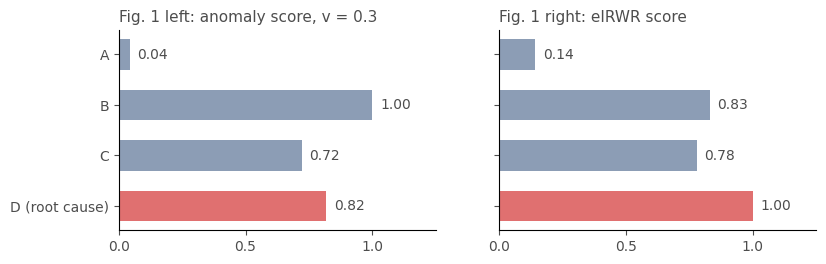

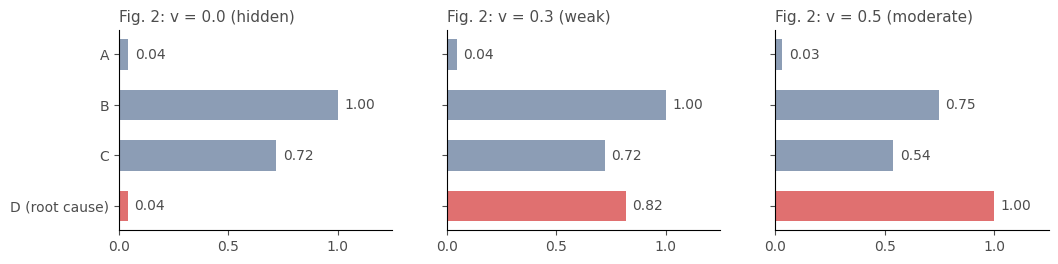

In [10]:
GRAY, RED, INK = "#8C9DB5", "#E07070", "#4D4D4D"
KEYS = ["A", "B", "C", "D"]


def panel(ax, values, title):
    y = np.arange(len(KEYS))[::-1]
    ax.barh(y, values, height=0.6, color=[RED if k == "D" else GRAY for k in KEYS])
    for yi, val in zip(y, values):
        ax.text(val + 0.03, yi, f"{val:.2f}", va="center", color=INK, fontsize=10)
    ax.set_yticks(y, ["A", "B", "C", "D (root cause)"])
    ax.set_xlim(0, 1.25)
    ax.set_xticks([0, 0.5, 1.0])
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(colors=INK)
    ax.grid(False)


fig, axes = plt.subplots(1, 2, figsize=(9, 2.6), sharey=True)
panel(axes[0], fig1_values.loc["anomaly score", KEYS].to_numpy(float),
      "Fig. 1 left: anomaly score, v = 0.3")
panel(axes[1], fig1_values.loc["eIRWR", KEYS].to_numpy(float),
      "Fig. 1 right: eIRWR score")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 2.6), sharey=True)
for ax, (v, tag) in zip(axes, [(0.0, "hidden"), (0.3, "weak"), (0.5, "moderate")]):
    panel(ax, fig2_values.loc[v, KEYS].to_numpy(float), f"Fig. 2: v = {v} ({tag})")
plt.show()

## How this incident was chosen

We searched CG84 for incidents with the pattern of Fig. 1: a caller of the root
cause has the highest anomaly score, and eIRWR still ranks the root cause first.
We kept `MS_71910` because its neighborhood matches the four-service graph of
Fig. 1 (two callers that share one caller). The result is also stable: in
Section 7, eIRWR ranks $D$ first in every noise draw, and $B$ is the most
anomalous service in nearly all of them. The example illustrates the mechanism.
It does not show how often eIRWR succeeds over all incidents.